<center>
    <p style="color: red; font-size: 20px;">Tên: Lê Thiên Hạo</p>
</center>
<center>
    <p style="color: red; font-size: 20px;">MSSV: 089206010393</p>
</center>

In [1]:
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

X_digits, y_digits = load_digits(return_X_y=True)

In [2]:
n_samples = len(X_digits)

In [3]:
X_train = X_digits[:int(0.9*n_samples)]
y_train = y_digits[:int(0.9*n_samples)]

X_test = X_digits[int(0.9*n_samples):]
y_test = y_digits[int(0.9*n_samples):]

In [4]:
knn = KNeighborsClassifier()
logistic = LogisticRegression(max_iter=1000)

In [5]:
print("KNN score: %f" % knn.fit(X_train, y_train).score(X_test, y_test))
print(
    "LogisticRegression score: %f"
    % logistic.fit(X_train, y_train).score(X_test, y_test)
)

KNN score: 0.961111
LogisticRegression score: 0.927778


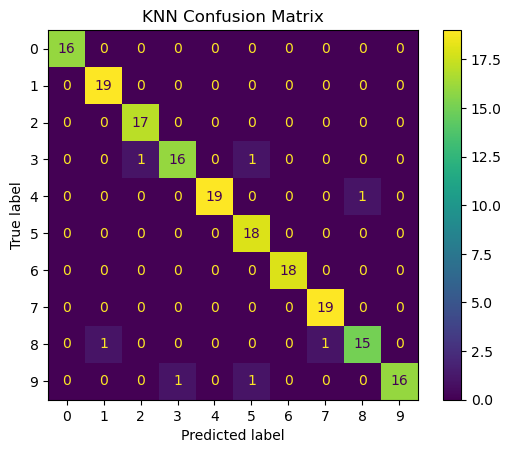

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

ConfusionMatrixDisplay.from_estimator(
    knn,
    X_test,
    y_test
)
plt.title("KNN Confusion Matrix")
plt.show()

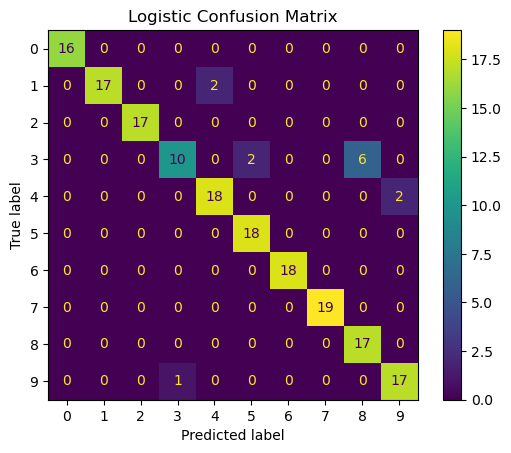

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

ConfusionMatrixDisplay.from_estimator(
    logistic,
    X_test,
    y_test
)
plt.title("Logistic Confusion Matrix")
plt.show()

In [38]:
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

Thử lần lượt các model:
- Nearest Neighbors
- Linear SVM
- RBF SVM
- Gaussian Process
- Decision Tree
- Random Forest
- Neural Net
- AdaBoost
- Naive Bayes

In [39]:
names = [
    "Nearest Neighbors",
    "Linear SVM",
    "RBF SVM",
    "Gaussian Process",
    "Decision Tree",
    "Random Forest",
    "Neural Net",
    "AdaBoost",
    "Naive Bayes",
]

In [40]:
classifiers = [
    KNeighborsClassifier(3),
    SVC(kernel="linear", C=0.025, random_state=42),
    SVC(gamma=2, C=1, random_state=42),
    GaussianProcessClassifier(1.0 * RBF(1.0), random_state=42),
    DecisionTreeClassifier(max_depth=5, random_state=42),
    RandomForestClassifier(
        max_depth=5, n_estimators=10, max_features=1, random_state=42
    ),
    MLPClassifier(alpha=1, max_iter=1000, random_state=42),
    AdaBoostClassifier(random_state=42),
    GaussianNB(),
]

In [56]:
for name, clf in zip(names, classifiers):
    clf = make_pipeline(StandardScaler(), clf) 
    clf.fit(X_train, y_train)

    pred = clf.predict(X_test)

    print(f"Classifier Model: {name}\nAccuracy: {accuracy_score(y_test, pred)}\n" + 20*'-')

Classifier Model: Nearest Neighbors
Accuracy: 0.95
--------------------
Classifier Model: Linear SVM
Accuracy: 0.9444444444444444
--------------------
Classifier Model: RBF SVM
Accuracy: 0.10555555555555556
--------------------
Classifier Model: Gaussian Process
Accuracy: 0.9611111111111111
--------------------
Classifier Model: Decision Tree
Accuracy: 0.6111111111111112
--------------------
Classifier Model: Random Forest
Accuracy: 0.7444444444444445
--------------------
Classifier Model: Neural Net
Accuracy: 0.9388888888888889
--------------------
Classifier Model: AdaBoost
Accuracy: 0.7166666666666667
--------------------
Classifier Model: Naive Bayes
Accuracy: 0.75
--------------------


# Model có điểm cao nhất là `Gaussian Process` với score là `0.96`

In [49]:
classifiers[3]

,kernel,1**2 * RBF(length_scale=1)
,optimizer,'fmin_l_bfgs_b'
,n_restarts_optimizer,0
,max_iter_predict,100
,warm_start,False
,copy_X_train,True
,random_state,42
,multi_class,'one_vs_rest'
,n_jobs,None
,kernel__k1,1**2
,kernel__k2,RBF(length_scale=1)


In [57]:
fitted_X_test = StandardScaler().fit_transform(X_test)

In [61]:
gaus_pred = classifiers[3].predict(fitted_X_test)

In [62]:
from sklearn.metrics import classification_report, accuracy_score
print(accuracy_score(y_test, gaus_pred))

0.9444444444444444


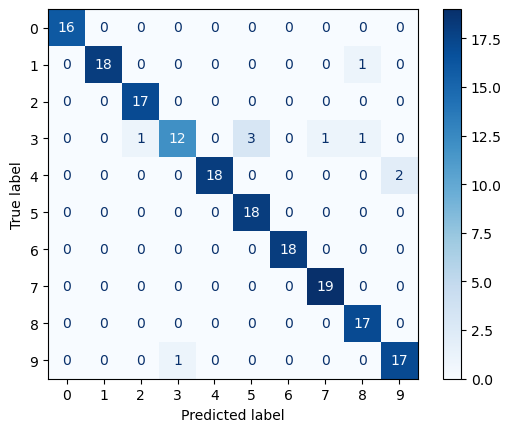

In [63]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, gaus_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)
disp.plot(cmap=plt.cm.Blues)
plt.show()